# ¿Le gana un modelo a los economistas pronosticando la inflación en Chile?

**Análisis exploratorio y resultados de la competencia.**
Datos del Banco Central de Chile (Base de Datos Estadísticos, BDE), propiedad del Banco Central. El análisis es mío.

Este notebook solo muestra y explica: los cálculos están en `src/inflacion/` (con tests) y los datos se actualizan solos
cada mes con GitHub Actions. Para correrlo de nuevo: `pip install -e ".[modelos]"` y después `python -m inflacion competir`
y `python -m inflacion graficos`.

In [1]:
import pandas as pd
from IPython.display import Image, display

from inflacion.dominio import analisis
from inflacion.presentacion.cli import DATA, RAIZ

pd.set_option("display.precision", 2)
panel = pd.read_csv(DATA / "panel_mensual.csv", index_col="mes", parse_dates=True)


def img(nombre):
    display(Image(filename=str(RAIZ / "docs" / "img" / f"{nombre}.png"), width=900))


pd.DataFrame(
    {
        "desde": panel.apply(lambda s: s.first_valid_index()).dt.strftime("%Y-%m"),
        "hasta": panel.apply(lambda s: s.last_valid_index()).dt.strftime("%Y-%m"),
        "meses": panel.notna().sum(),
    }
)

,desde,hasta,meses
ipc_mensual,2000-01,2026-10,322
ipc_12m,2000-01,2026-10,322
ipc_sae_mensual,2018-02,2026-10,105
dolar,2000-01,2026-11,323
tpm,2000-01,2026-11,323
cobre,2000-01,2026-10,322
imacec,2000-01,2026-09,321
eee_mes,2000-02,2026-11,322
eee_mes_siguiente,2010-02,2026-11,202
eee_12m_en_11,2001-01,2026-11,304


## 1. Los datos

Un panel mensual desde 2000 con diez series. Las diarias (dólar y tasa) se pasan a mensual: el dólar como promedio del mes
y la tasa como el último dato. Las que cambiaron de base (el IPC SAE) se empalman.

Las tres series `eee_*` son la **Encuesta de Expectativas Económicas**: la mediana de lo que esperan los economistas
consultados por el Banco Central. Son el rival a vencer.

## 2. Veintiséis años de inflación

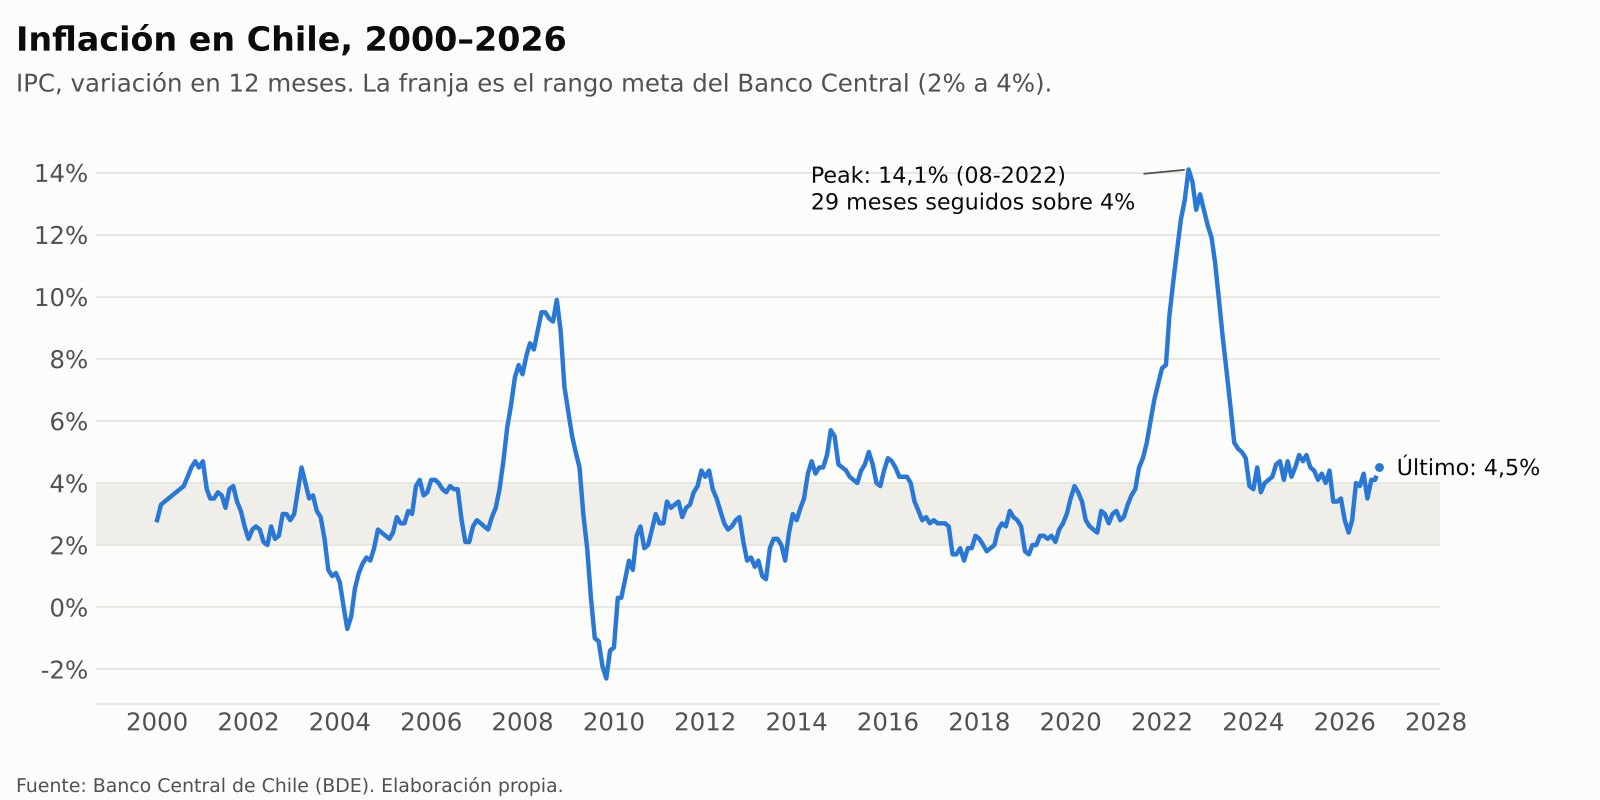

Episodio más largo sobre el 4%: 07-2021 a 11-2023 (29 meses), peak 14.1% en 08-2022.
Promedio 2010-2019: 2.9%


In [2]:
ep = analisis.episodio_alto(panel["ipc_12m"])
img("01_inflacion_historica")
print(
    f"Episodio más largo sobre el 4%: {ep['desde']:%m-%Y} a {ep['hasta']:%m-%Y} ({ep['meses']} meses), "
    f"peak {ep['peak']}% en {ep['mes_peak']:%m-%Y}."
)
print(f"Promedio 2010-2019: {panel['ipc_12m'].loc['2010':'2019'].mean():.1f}%")

Entre 2010 y 2019 la inflación promedió cerca del 3%, justo en la meta. Después vino el episodio más largo del
período: casi dos años y medio sobre el techo del rango, con un peak de 14,1% en agosto de 2022, el más alto de toda la
serie. La otra subida fuerte, la de 2008, fue más corta y terminó en deflación en 2009.

## 3. ¿Fue solo la comida y la energía?

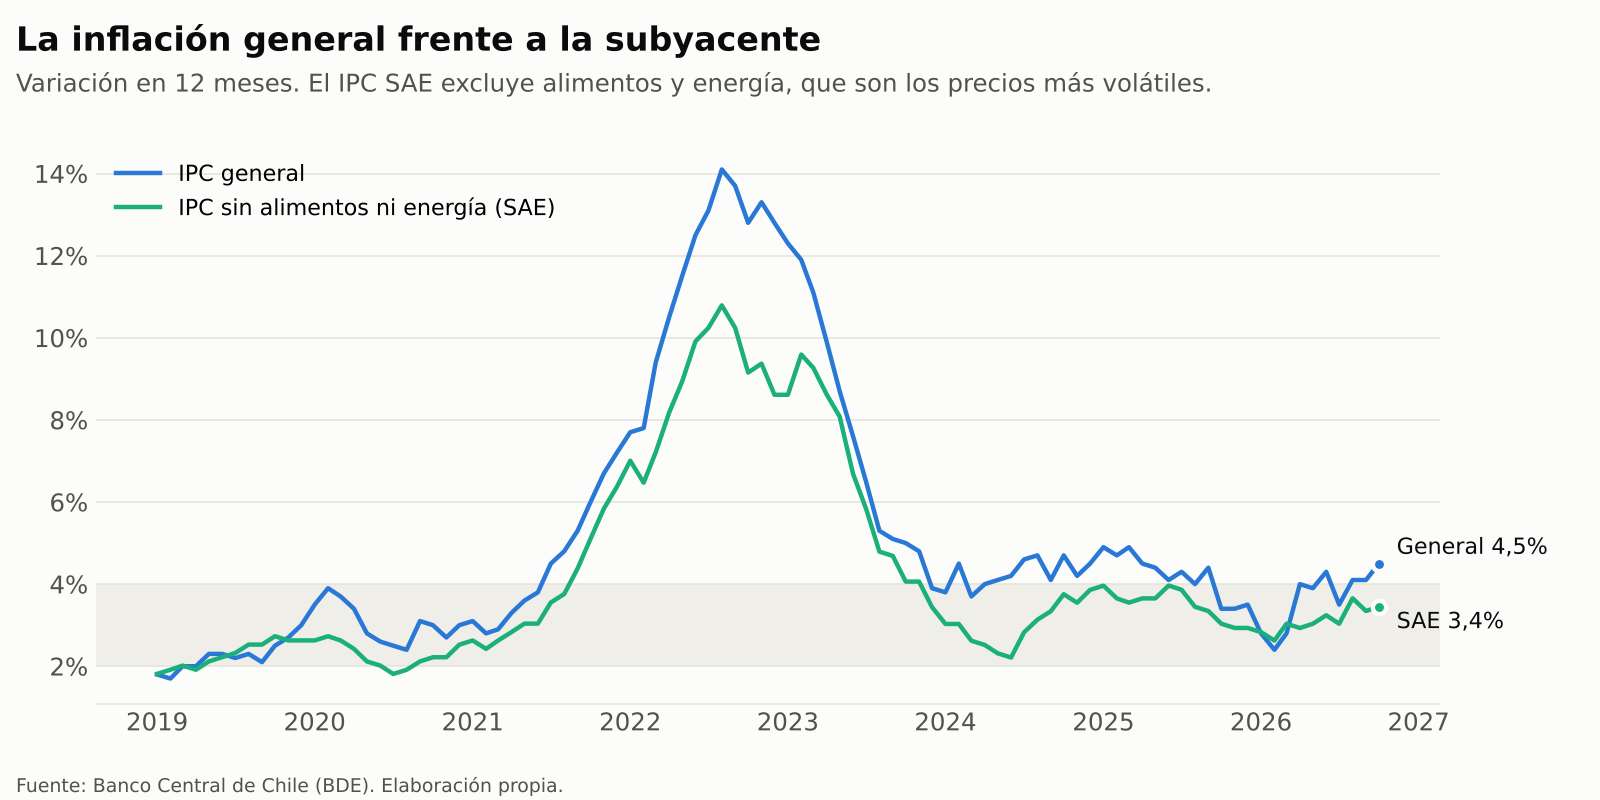

Peak IPC SAE: 10.8% en 08-2022. Último: 3.4%


In [3]:
sae = analisis.acumulada_12m(panel["ipc_sae_mensual"])
img("02_general_vs_subyacente")
print(f"Peak IPC SAE: {sae.max():.1f}% en {sae.idxmax():%m-%Y}. Último: {sae.dropna().iloc[-1]:.1f}%")

No. El IPC sin alimentos ni energía también llegó a 10,8%. Cuando la inflación subyacente sube así, el problema
no es un precio puntual sino que los precios en general se están ajustando hacia arriba (demanda, indexación, salarios).
Por eso costó tanto bajarla. Hoy la subyacente está más cerca de la meta que la general.

## 4. Los meses en que más suben los precios

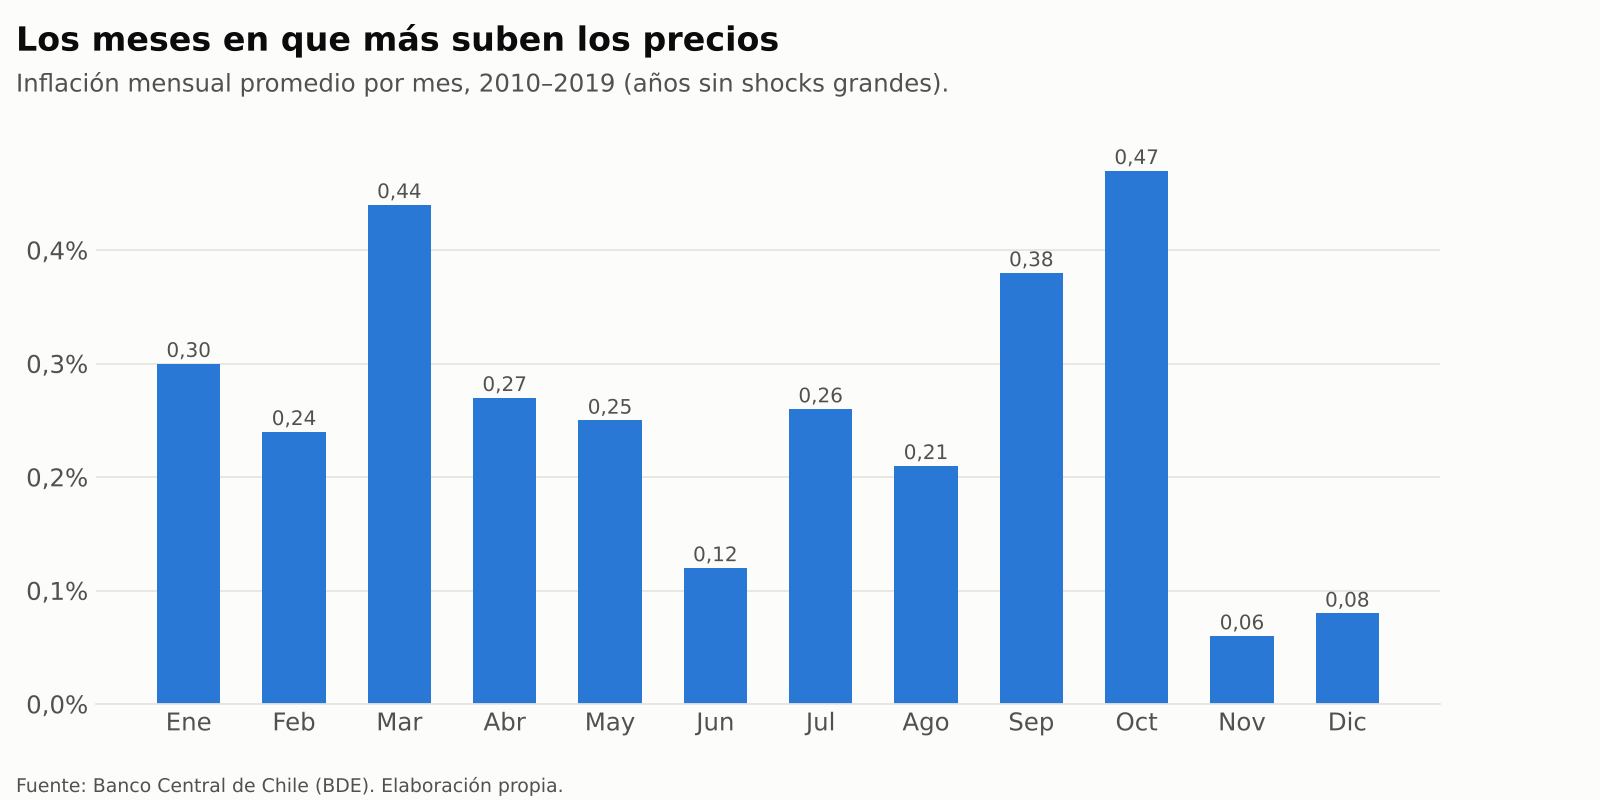

mes,1,2,3,4,5,6,7,8,9,10,11,12
promedio_%,0.3,0.24,0.44,0.27,0.25,0.12,0.26,0.21,0.38,0.47,0.06,0.08


In [4]:
img("03_estacionalidad")
analisis.estacionalidad(panel["ipc_mensual"], "2010", "2019").rename("promedio_%").to_frame().T

La inflación mensual tiene un patrón claro: marzo (matrículas y colegios), septiembre y octubre suben más;
noviembre y diciembre casi nada. Cualquier modelo de inflación mensual tiene que capturar esto. Por eso el modelo
"mismo mes del año anterior" es una referencia razonable y los modelos de machine learning reciben el mes calendario.

## 5. ¿Cuánto del dólar llega a los precios?

In [5]:
tramos = {"2001-2026": ("2001", "2026"), "2010-2019": ("2010", "2019")}
filas = []
for nombre, (a, b) in tramos.items():
    t = analisis.traspaso_dolar(panel.loc[a:b], 12)
    k = int(t.loc[t["correlacion"].idxmax(), "rezago"])
    filas.append(
        {
            "periodo": nombre,
            "rezago_meses": k,
            "correlacion": t["correlacion"].max(),
            "pp_por_cada_10%_del_dolar": analisis.coeficiente_traspaso(panel.loc[a:b], k),
        }
    )
pd.DataFrame(filas)

,periodo,rezago_meses,correlacion,pp_por_cada_10%_del_dolar
0,2001-2026,0,0.33,0.79
1,2010-2019,2,0.61,0.75


Este resultado fue más débil de lo que esperaba, y lo dejo así. Mirando todo el período la relación es floja
(correlación 0,33): en 2008 y en 2022 la inflación subió por muchas cosas a la vez (combustibles, alimentos, retiros de
fondos de pensiones) y el dólar explica solo una parte. En la década tranquila (2010-2019) la relación es mucho más clara:
correlación 0,61 con unos dos meses de rezago, y cada 10% que sube el dólar viene con unos 0,75 puntos más de inflación.

Ojo: es correlación, no causalidad. Sirve para saber qué variables vale la pena darle a un modelo, no para afirmar un efecto.

## 6. Cómo respondió el Banco Central

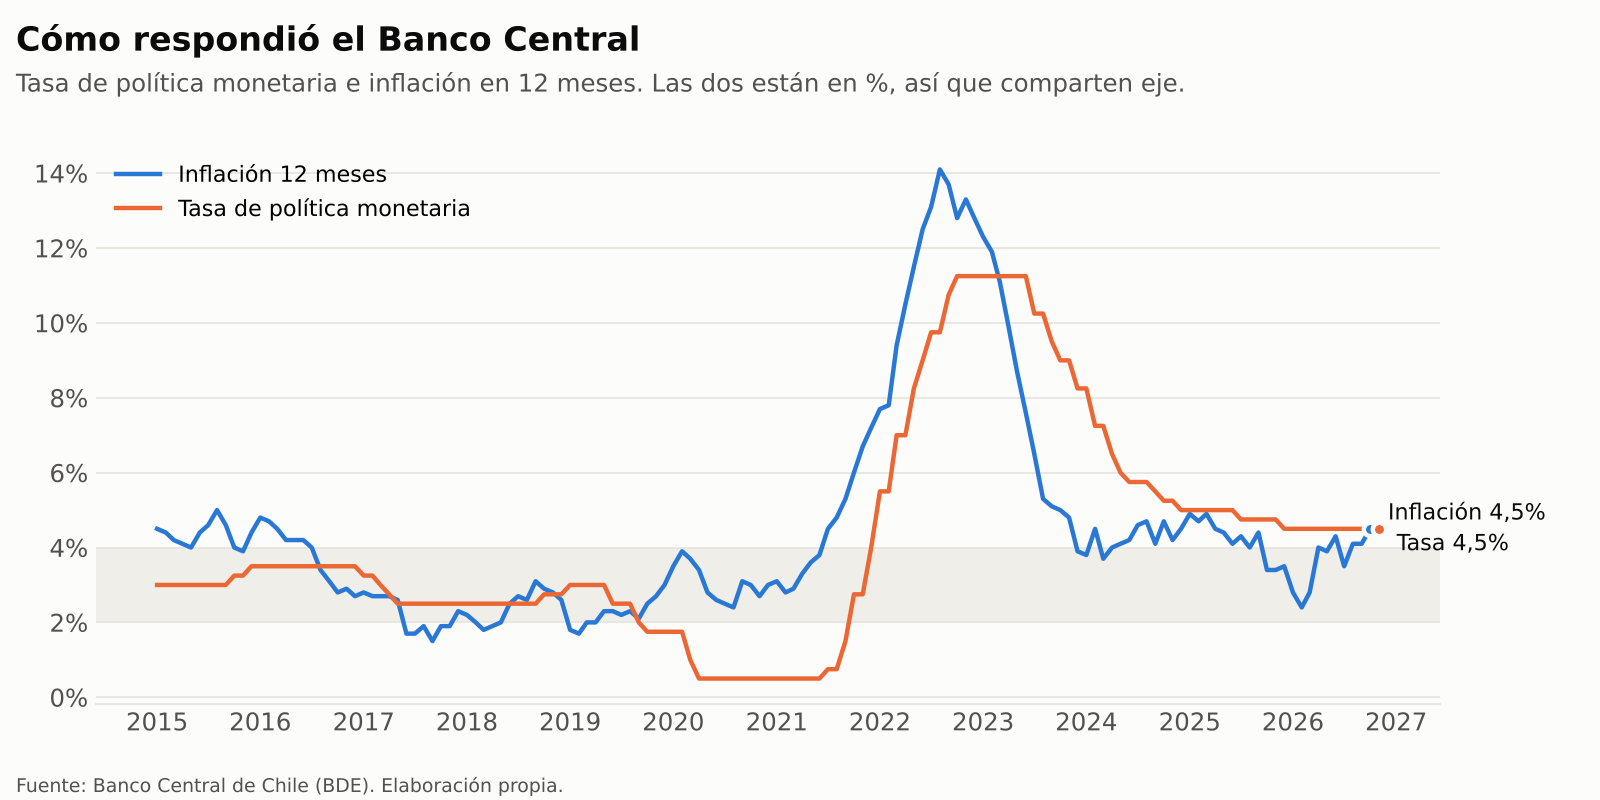

Tasa en 2020-2021: 0.5% | peak: 11.25% (10-2022 a 06-2023)
Tasa real esperada, máximo: 7.2 puntos en 06-2023


In [6]:
tpm = panel["tpm"]
real = analisis.tasa_real_esperada(panel)
img("04_tasa_e_inflacion")
print(f"Tasa en 2020-2021: {tpm.loc['2020-06':'2021-06'].min()}% | peak: {tpm.max()}% (10-2022 a 06-2023)")
tramo = real.loc["2022":"2024"]
print(f"Tasa real esperada, máximo: {tramo.max():.1f} puntos en {tramo.idxmax():%m-%Y}")

La tasa estuvo en 0,5% durante la pandemia y empezó a subir en julio de 2021, cuando la inflación ya iba en 4,5%.
Llegó a 11,25% y se mantuvo ahí nueve meses. Recién cuando la tasa quedó muy por sobre la inflación esperada (una tasa
real de unos 7 puntos a mediados de 2023) la inflación bajó con fuerza. Desde entonces el Banco Central ha ido bajando
la tasa de a poco.

## 7. Lo que esperaban los economistas

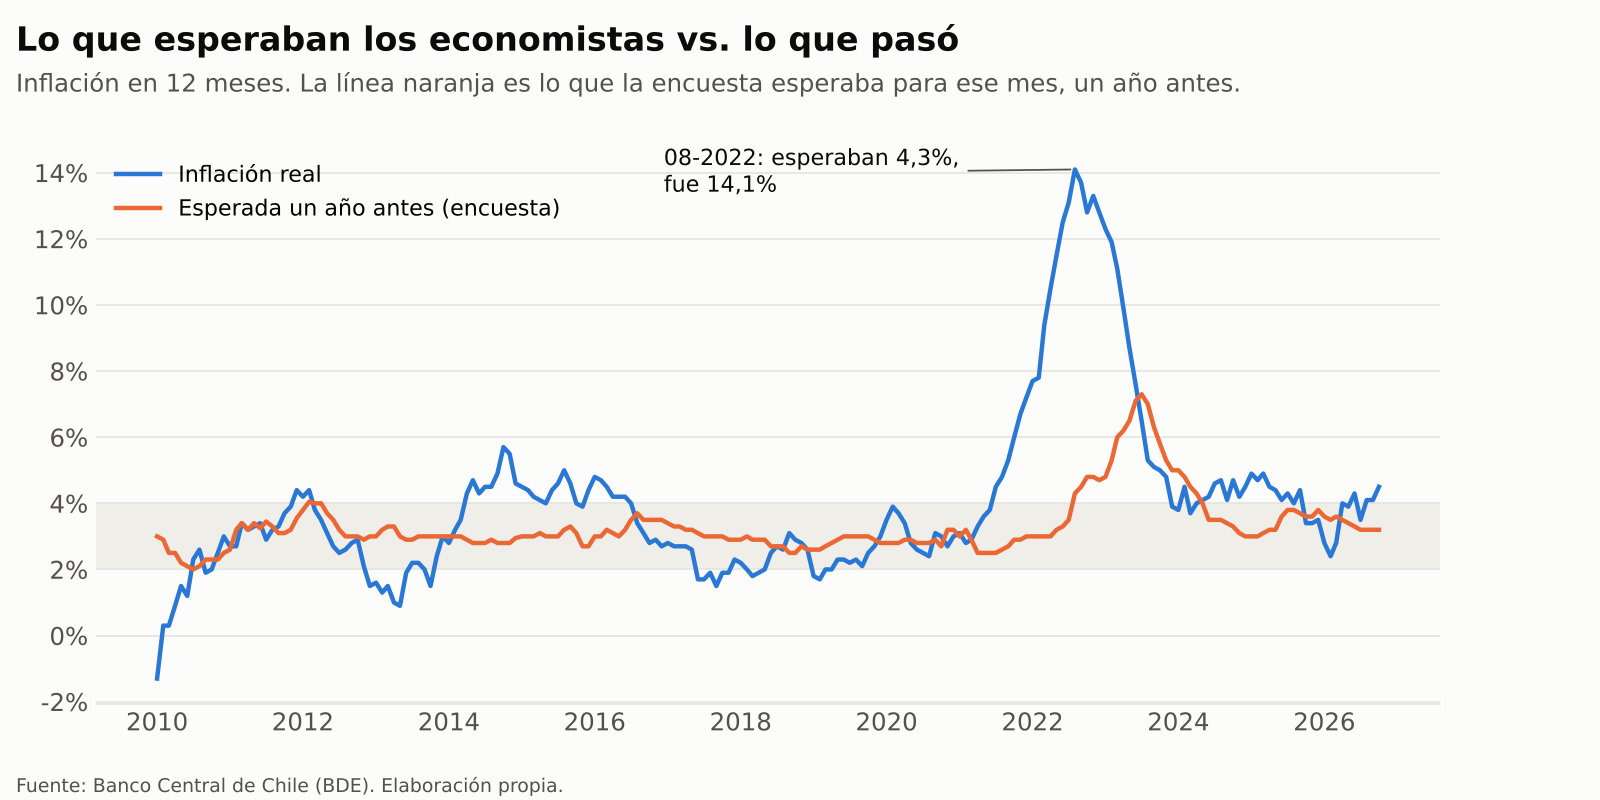

,sesgo_medio_pp,error_abs_medio_pp
2010-2019,0.11,0.92
2020-2023,-2.84,3.18
2024-2026,-0.50,0.85


In [7]:
errores = analisis.errores_encuesta(panel)
img("05_esperado_vs_real")
periodos = {"2010-2019": ("2010", "2019"), "2020-2023": ("2020", "2023"), "2024-2026": ("2024", "2026")}
pd.DataFrame(
    {
        nombre: {
            "sesgo_medio_pp": errores.loc[a:b, "error"].mean(),
            "error_abs_medio_pp": errores.loc[a:b, "error"].abs().mean(),
        }
        for nombre, (a, b) in periodos.items()
    }
).T

En la década tranquila los economistas casi no tenían sesgo (+0,1 puntos). En el shock se quedaron cortos por casi
3 puntos en promedio: en septiembre de 2021 esperaban 4,3% para agosto de 2022, y fue 14,1%. Lo más interesante es lo
que pasa después: desde 2024 siguen subestimando la inflación (−0,5 puntos en promedio), como si siguieran anclados a la meta del 3%.

## 8. La competencia

Para cada mes desde 2010, cada modelo pronostica usando **solo lo que se sabía el día en que los economistas respondieron**
la encuesta (cerca del día 10): el IPC hasta el mes anterior, el dólar y la tasa del mes anterior, y el Imacec de dos meses
atrás, porque sale con rezago. Los modelos se vuelven a entrenar cada mes con los datos disponibles hasta ese momento.
Hay tests que verifican esto cambiando "el futuro" y comprobando que el pronóstico no se mueve.

Dos preguntas:
- **Inflación del mes:** la variación mensual del IPC del mes de la encuesta.
- **Inflación en 12 meses, a un año:** la variación en 12 meses que habrá 11 meses después.

Para separar una diferencia real de la suerte uso el test de Diebold-Mariano: un valor p bajo 0,05 dice que la diferencia
con los economistas es estadísticamente significativa.

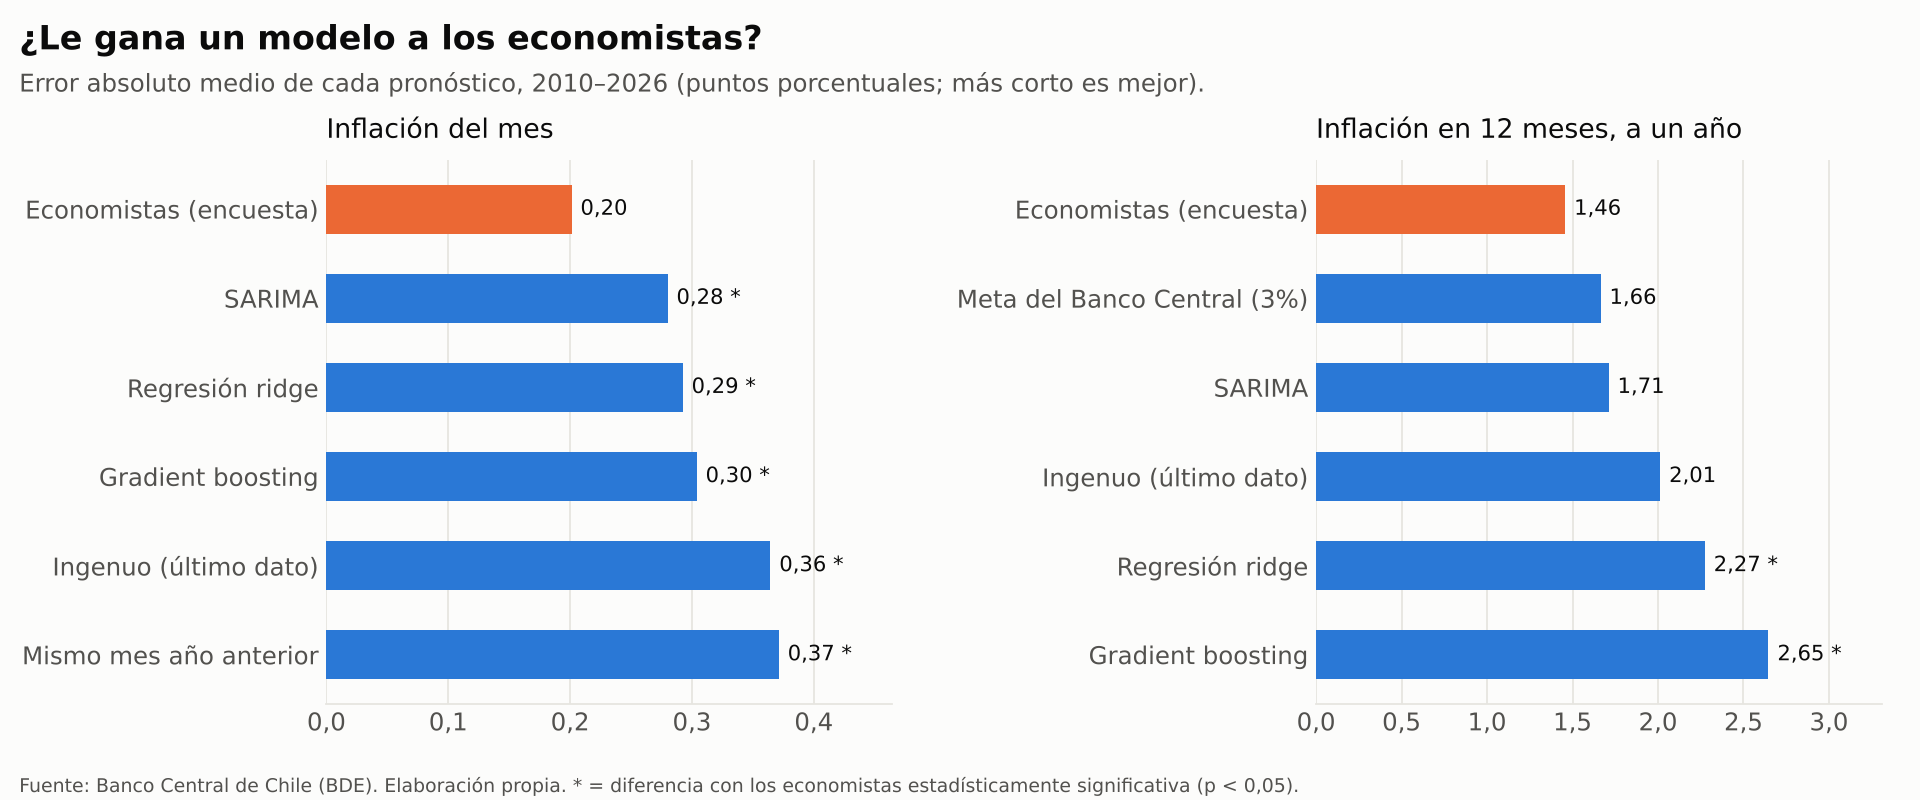

,tarea,competidor,meses,error_abs_medio,rmse,vs_economistas,p_valor
0,Inflación del mes,Economistas (encuesta),202,0.20,0.27,1.00,NaN
1,Inflación del mes,Ingenuo (último dato),202,0.36,0.47,1.81,0.00
2,Inflación del mes,Mismo mes año anterior,202,0.37,0.48,1.85,0.00
3,Inflación del mes,SARIMA,202,0.28,0.36,1.39,0.00
4,Inflación del mes,Regresión ridge,202,0.29,0.38,1.45,0.00
5,Inflación del mes,Gradient boosting,202,0.30,0.38,1.51,0.00
24,"Inflación en 12 meses, a un año",Economistas (encuesta),191,1.46,2.45,1.00,NaN
25,"Inflación en 12 meses, a un año",Ingenuo (último dato),191,2.01,3.03,1.38,0.32
26,"Inflación en 12 meses, a un año",Meta del Banco Central (3%),191,1.66,2.84,1.14,0.30
27,"Inflación en 12 meses, a un año",SARIMA,191,1.71,2.74,1.17,0.40


In [8]:
resumen = pd.read_csv(DATA / "resultados" / "resumen.csv")
img("06_resultados")
(
    resumen[resumen["periodo"] == "Todo"]
    .loc[:, ["tarea", "competidor", "meses", "mae", "rmse", "mae_vs_economistas", "p_valor"]]
    .rename(columns={"mae": "error_abs_medio", "mae_vs_economistas": "vs_economistas"})
)

In [9]:
(
    resumen.pivot_table(index=["tarea", "competidor"], columns="periodo", values="mae")[
        ["2010-2019 (inflación tranquila)", "2020-2023 (pandemia y shock)", "2024 en adelante", "Todo"]
    ]
)

periodo                                                      2010-2019 (inflación tranquila)  \
tarea                           competidor                                                     
Inflación del mes               Economistas (encuesta)                                  0.17   
                                Gradient boosting                                       0.26   
                                Ingenuo (último dato)                                   0.29   
                                Mismo mes año anterior                                  0.31   
                                Regresión ridge                                         0.25   
                                SARIMA                                                  0.24   
Inflación en 12 meses, a un año Economistas (encuesta)                                  0.85   
                                Gradient boosting                                       1.86   
                                Ingenuo (último dato)                                   1.24   
                                Meta del Banco Central (3%)                             0.85   
                                Regresión ridge                                         1.48   
                                SARIMA                                                  0.94   

periodo                                                      2020-2023 (pandemia y shock)  \
tarea                           competidor                                                  
Inflación del mes               Economistas (encuesta)                               0.28   
                                Gradient boosting                                    0.39   
                                Ingenuo (último dato)                                0.45   
                                Mismo mes año anterior                               0.52   
                                Regresión ridge                                      0.36   
                                SARIMA                                               0.34   
Inflación en 12 meses, a un año Economistas (encuesta)                               3.26   
                                Gradient boosting                                    5.25   
                                Ingenuo (último dato)                                4.52   
                                Meta del Banco Central (3%)                          3.99   
                                Regresión ridge                                      4.73   
                                SARIMA                                               4.11   

periodo                                                      2024 en adelante  \
tarea                           competidor                                      
Inflación del mes               Economistas (encuesta)                   0.18   
                                Gradient boosting                        0.35   
                                Ingenuo (último dato)                    0.50   
                                Mismo mes año anterior                   0.38   
                                Regresión ridge                          0.35   
                                SARIMA                                   0.34   
Inflación en 12 meses, a un año Economistas (encuesta)                   0.87   
                                Gradient boosting                        1.30   
                                Ingenuo (último dato)                    0.80   
                                Meta del Banco Central (3%)              1.06   
                                Regresión ridge                          1.32   
                                SARIMA                                   0.74   

periodo                                                      Todo  
tarea                           competidor                         
Inflación del mes               Economistas (encuesta)       0.20  
             

## 9. Conclusiones

1. **En la inflación del mes, los economistas ganan claro.** Se equivocan en promedio 0,20 puntos; el mejor modelo
   (SARIMA), 0,28. La diferencia es significativa en todos los modelos. Tiene sentido: responden cerca del día 10, cuando
   ya ven parte de los precios del mes (bencinas, alimentos, el dólar de esos días). Los modelos no tienen esa información.
2. **A un año, los economistas no le ganan de forma demostrable a una regla simple.** Su error es 1,46 puntos; apostar
   siempre por la meta del 3% da 1,66 y un SARIMA da 1,71, y en ninguno de los dos casos la diferencia es significativa
   (p ≈ 0,3). Los modelos con más variables (ridge y gradient boosting) son peores: con unos 250 meses de historia y un
   shock que no se parece a nada anterior, aprender relaciones complejas no paga.
3. **Desde 2024 el SARIMA (0,74) y hasta el modelo ingenuo (0,80) se equivocan menos que los economistas (0,87) a un año**,
   que siguen subestimando la inflación. Son pocos meses para concluir algo firme, pero vale la pena seguirlo: el
   proyecto se actualiza solo cada mes.
4. **En el shock de 2021-2022 fallaron todos.** Ningún modelo basado en el pasado podía anticipar algo así, y los
   economistas tampoco.

**Límites:** es un solo país y un período con un shock enorme que pesa mucho en los promedios; la encuesta es una mediana
y no un pronóstico individual; y los modelos no usan información dentro del mes, como sí la tienen los economistas.
Lo siguiente que probaría es darles a los modelos los primeros días del mes (dólar diario, precio de los combustibles)
para emparejar la cancha.